 02 - Exploring Topics in Negative Reviews

  Goal --
Identify recurring issues customers mention in negative restaurant reviews and explore whether the themes vary across restaurant categories.

 Questions
- What topics appear most often in negative reviews? (could be anything entirely)
- Which topics are common across categories, and which seem more specific to certain categories? 


 Approach -- 
We’ll prepare the review text,find the reviews that are not in the category of restaurants tht have to do with them , explore recurring words or themes, and compare the results across categories where the data supports it.

In [ ]:
from getpass import getpass     # connected to database to get some example reviews
import pandas as pd
from sqlalchemy import create_engine, inspect, text
from sqlalchemy.engine import URL

password = getpass("PostgreSQL password: ")
engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="yelp_project",
))

columns = [column["name"] for column in inspect(engine).get_columns("reviews", schema="clean")]
print("Review table columns:", columns)

text_columns = [
    column for column in columns
    if column.lower() in {"text", "review_text", "review"}
]

if not text_columns:
    print("No obvious review-text column found. Check the column list above.")
else:
    text_column = text_columns[0]
    query = text(
        f'SELECT review_id, stars, star_group, "{text_column}" AS review_text '
        "FROM clean.reviews "
        "WHERE star_group = :group "
        "LIMIT 5"
    )
    examples = pd.read_sql_query(query, engine, params={"group": "negative"})
    print(examples[["review_id", "stars", "review_text"]].to_string(index=False))



    # checking my connection to the database...and an example query to get some data from the reviews table.

Review table columns: ['review_id', 'user_id', 'business_id', 'stars', 'star_group', 'review_datetime', 'review_date', 'review_year', 'review_month', 'is_partial_year', 'useful_votes', 'funny_votes', 'cool_votes', 'review_text', 'text_length', 'is_short_review', 'has_url']
             review_id  stars                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         

In [ ]:
check_categories = text("""
    SELECT r.review_id, r.business_id, c.category
    FROM clean.reviews AS r
    JOIN clean.business_categories AS c USING (business_id)
    WHERE r.review_id = :review_id
    ORDER BY c.category
""")

pd.read_sql_query(
    check_categories,
    engine,
    params={"review_id": "-nQRvxUGWYUBqTZdcyvprQ"},  # selected this particular id
)

# checking the categories for a specific review to see if the join works correctly.
# this is just to find the reviews for restuarants only 

# ISSUE - some other categories might have restuarant reviews because the business has multiple categories. 
# For example, a business could be both a "restaurant" and a "bar", and the review might be about the bar aspect. 
# So we need to filter for reviews that are specifically about restaurants.


# SOLUTION - filter for reviews that are specifically about restaurants

# Purely restaurants by category : keep every review.
# Mixed businesses: keep a review only if its text is mostly about dining, 
# meaning it mentions food, the menu, servers, dishes and so on more than rooms, the cover charge, gas pumps and so on.

,review_id,business_id,category
0,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Event Planning & Services
1,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Hotels
2,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Hotels & Travel
3,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Restaurants
4,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Venues & Event Spaces


In [ ]:
# load ALL reviews + mark businesses whose tags are mixed (not purely a restaurant)
import re  # like ctrl+f but it can match any words and their variations at once 

MIXED_TAGS = [
    "Nightlife", "Bars", "Hotels", "Hotels & Travel", "Casinos",
    "Venues & Event Spaces", "Event Planning & Services", "Arts & Entertainment",
    "Grocery", "Convenience Stores", "Gas Stations",
]

reviews = pd.read_sql_query(text("""
    SELECT r.review_id, r.business_id, r.stars, r.star_group, r.review_text,
           EXISTS (SELECT 1 FROM clean.business_categories c
                   WHERE c.business_id = r.business_id
                     AND c.category = ANY(:mixed_tags)) AS is_mixed_business
    FROM clean.reviews r
"""), engine, params={"mixed_tags": MIXED_TAGS})

print(f"{len(reviews):,} reviews | from mixed businesses: {reviews.is_mixed_business.mean():.1%}")

# shows the percentage of mixed reviews from the total number of reviews 


307,510 reviews | from mixed businesses: 35.9%


In [ ]:
# Word lists: words that show a review is about eating at the restaurant, and words that show it's about something else
# This is basically AI analysis - AI helped me generate this code to look for reviews that have to do with dining , restaurants and any others of the sort 


DINING_WORDS = r"""\b(?:food|dish(?:es)?|meals?|menu|order(?:ed)?|servers?|waiter|waitress|waitstaff|
    ate|eat(?:ing)?|tast(?:e|ed|y|eless)|flavou?r|bland|(?:under|over)?cooked|chef|kitchen|
    appetizers?|entrees?|desserts?|lunch|dinner|breakfast|brunch|burgers?|pizza|sandwich(?:es)?|
    salads?|steak|chicken|fries|sushi|tacos?|wings|soup|sauce|portions?|plates?|restaurant|
    reservation|delicious|soggy|greasy|buffet|takeout|delivery|seafood|fish|bread|rice)\b"""

NON_DINING_WORDS = r"""\b(?:(?<!dining )rooms?|beds?|front desk|check[- ]?in|check[- ]?out|housekeeping|
    lobby|pool|casino|slots?|concert|tickets?|stage|cover charge|bouncers?|dj|dance floor|
    gas|pumps?|aisles?|groceries)\b"""

dining_re = re.compile(DINING_WORDS, re.IGNORECASE | re.VERBOSE)
non_dining_re = re.compile(NON_DINING_WORDS, re.IGNORECASE | re.VERBOSE)

# Count how many times each kind of word appears in every review
reviews["dining_hits"] = reviews.review_text.str.count(dining_re)
reviews["non_dining_hits"] = reviews.review_text.str.count(non_dining_re)

reviews[["review_text", "dining_hits", "non_dining_hits"]].head()   # checking those 5 rows to see how many dining words were in the review sentence 


,review_text,dining_hits,non_dining_hits
0,Family diner. Had the buffet. Eclectic assortm...,5,0
1,Good food--loved the gnocchi with marinara\nth...,3,0
2,Tremendous service (Big shout out to Douglas) ...,2,0
3,Best thai food in the area. Everything was au...,2,0
4,My go to menu is coconut soup and pad thai wit...,8,0


In [6]:
# A review is "about dining" if it has at least 1 dining word AND at least as many dining words as non-dining words
about_dining = (reviews.dining_hits >= 1) & (reviews.dining_hits >= reviews.non_dining_hits)

# Pure restaurant -> always keep (its tags already tell the truth)
# Mixed business  -> keep only if the text is about dining
reviews["is_restaurant_review"] = (~reviews.is_mixed_business) | about_dining

mixed = reviews[reviews.is_mixed_business]
print(f"Mixed-business reviews kept: {mixed.is_restaurant_review.sum():,} of {len(mixed):,} ({mixed.is_restaurant_review.mean():.1%})")
print(f"All reviews kept:            {reviews.is_restaurant_review.sum():,} of {len(reviews):,}")


Mixed-business reviews kept: 99,284 of 110,286 (90.0%)
All reviews kept:            296,508 of 307,510


In [7]:
# Read 10 reviews it kept and 10 it dropped, all from mixed businesses
pd.set_option("display.max_colwidth", 300)
for label, keep in [("KEPT", True), ("DROPPED", False)]:
    print(f"\n===== {label} =====")
    sample = mixed[mixed.is_restaurant_review == keep].sample(10, random_state=42)
    print(sample[["stars", "dining_hits", "non_dining_hits", "review_text"]].to_string(index=False))



===== KEPT =====
 stars  dining_hits  non_dining_hits                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

THIS IS THE NEGATIVE REVIEW ASPECT WHERE YOU CAN SEE WHAT TOPICS CAUSE THE MOST NEGATIVE REVIEWS 

(1) Define complaint topics, each with a list of words people use when they complain about it (the same word-spotter idea as before).

(2) Tag every restaurant review with the topics it mentions. One review can mention several.

(3) Count how often each topic shows up in negative reviews. That's what people complain about most.

(4) Compare with positive reviews. A word like "price" turns up in happy reviews too, so a topic only counts as a real complaint if it's much more common in negative reviews.



In [9]:
# Final datasets: keep only the reviews that are about restaurants (pure restaurants + dining reviews from mixed businesses)
restaurant_reviews = reviews[reviews.is_restaurant_review].copy()
print(f"Restaurant reviews kept for the topic analysis: {len(restaurant_reviews):,}")

Restaurant reviews kept for the topic analysis: 296,508


In [10]:
# Each topic = words people typically use when complaining about it
TOPICS = {
    "Food quality":     r"\b(?:cold|bland|tasteless|flavou?rless|undercooked|overcooked|raw|stale|burnt|burned|soggy|greasy|salty|dry|inedible|frozen|microwaved|gross|disgusting|nasty)\b",
    "Rude service":     r"\b(?:rude|attitude|ignored|unprofessional|unfriendly|disrespectful|condescending|yelled|unhelpful|didn'?t care|manager)\b",
    "Long wait":        r"\b(?:wait(?:ed|ing)?|slow|forever|took (?:so |too )?long|\d+\s*(?:minutes|mins|hours?)|an hour)\b",
    "Wrong order":      r"\b(?:wrong (?:order|item|food|dish)|got the wrong|missing|forgot|forgotten|never (?:came|arrived)|mixed up|incorrect|left out)\b",
    "Price / value":    r"\b(?:overpriced|expensive|pricey|prices?|priced|overcharged|charged?|bill|money|not worth|rip[- ]?off|refund)\b",
    "Cleanliness":      r"\b(?:dirty|filthy|sticky|unsanitary|hair|flies|bugs?|roach(?:es)?|cockroach(?:es)?|mou?ld(?:y)?|smell(?:s|ed|y)?|stinks?)\b",
    "Got sick":         r"\b(?:sick|food poisoning|vomit(?:ed|ing)?|diarrh(?:ea|oea)|threw up|throwing up|stomach)\b",
    "Atmosphere":       r"\b(?:loud|noisy|music|crowded|cramped|decor|ambian(?:c|s)e|atmosphere)\b",
}

# Tag every restaurant review: True if it mentions the topic at least once
for topic, pattern in TOPICS.items():
    restaurant_reviews[topic] = restaurant_reviews.review_text.str.contains(
        re.compile(pattern, re.IGNORECASE)
    )

topic_names = list(TOPICS)
negative_reviews = restaurant_reviews[restaurant_reviews.star_group == "negative"]
positive_reviews = restaurant_reviews[restaurant_reviews.star_group == "positive"]
print(f"Negative: {len(negative_reviews):,} | Positive: {len(positive_reviews):,}")


Negative: 60,586 | Positive: 201,839


In [14]:
# What do negative reviews complain about most?
# .mean() on a True/False column = share of reviews that mention the topic
topic_summary = pd.DataFrame({
    "share_of_negative": negative_reviews[topic_names].mean(),
    "share_of_positive": positive_reviews[topic_names].mean(),
})
# How many times more common the topic is in negative reviews than in positive ones
# 1x = people mention it just as much when happy (weak complaint signal), 5x = clearly a complaint
topic_summary["times_more_in_negative"] = topic_summary.share_of_negative / topic_summary.share_of_positive
topic_summary = topic_summary.sort_values("share_of_negative", ascending=False)

untagged = (~negative_reviews[topic_names].any(axis=1)).mean()
print(f"Negative reviews matching NO topic: {untagged:.1%}")
print("Note: one review can mention several topics, so the shares add up to more than 100%.")

# Show the table with readable % values (no extra library needed)
display_table = topic_summary.copy()
display_table["share_of_negative"] = display_table.share_of_negative.map("{:.1%}".format)
display_table["share_of_positive"] = display_table.share_of_positive.map("{:.1%}".format)
display_table["times_more_in_negative"] = display_table.times_more_in_negative.map("{:.1f}x".format)
display_table


Negative reviews matching NO topic: 18.7%
Note: one review can mention several topics, so the shares add up to more than 100%.


,share_of_negative,share_of_positive,times_more_in_negative
Food quality,35.0%,8.1%,4.3x
Long wait,34.8%,15.5%,2.2x
Price / value,29.8%,16.6%,1.8x
Rude service,20.0%,2.4%,8.4x
Atmosphere,9.2%,17.2%,0.5x
Cleanliness,8.7%,1.9%,4.5x
Wrong order,7.1%,1.6%,4.6x
Got sick,3.2%,0.5%,6.2x


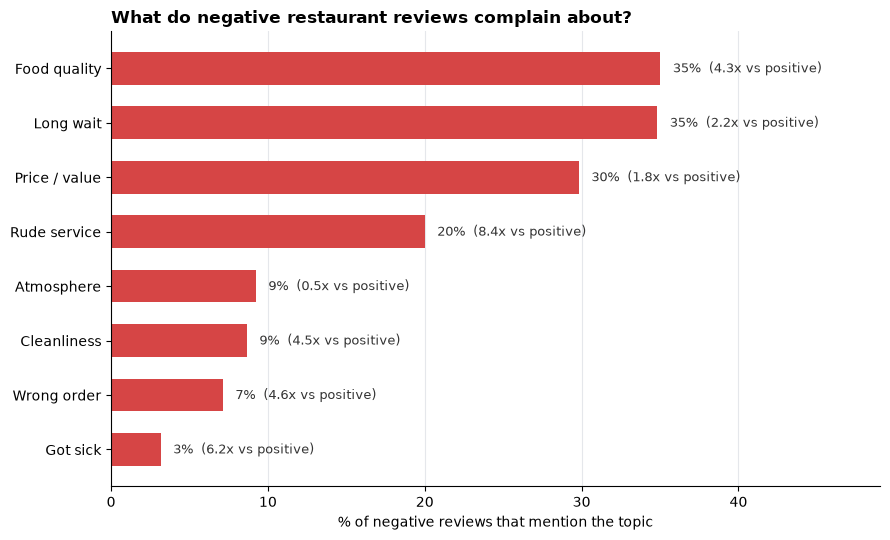

In [15]:
# Chart: share of negative reviews that mention each topic (biggest at the top)
import matplotlib.pyplot as plt

plot_data = topic_summary.sort_values("share_of_negative")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_data.index, plot_data.share_of_negative * 100, color="#D64545", height=0.6)

# Label each bar with its % and how much more common it is in negative than positive reviews
for y, (share, lift) in enumerate(zip(plot_data.share_of_negative, plot_data.times_more_in_negative)):
    ax.text(share * 100 + 0.8, y, f"{share:.0%}  ({lift:.1f}x vs positive)",
            va="center", fontsize=9, color="#333333")

ax.set_xlabel("% of negative reviews that mention the topic")
ax.set_title("What do negative restaurant reviews complain about?", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, plot_data.share_of_negative.max() * 100 * 1.4)
plt.tight_layout()
plt.show()

In [16]:
# Sanity check: read 3 real negative reviews per topic to confirm the tags make sense
pd.set_option("display.max_colwidth", 250)
for topic in topic_names:
    print(f"\n===== {topic} =====")
    print(negative_reviews.loc[negative_reviews[topic], "review_text"].sample(3, random_state=1).to_string(index=False))


===== Food quality =====
Ok...I've been on a best burger in St. Louis quest for awhile..I read the reviews on here so decided to check it out. First off waited 45 minutes for a table for five of us. Dont mind the wait if its worth it.  The place is loud.  Couldn't hear ea...
Because this place came so highly recommended, we had decided that we needed to stop at Brophy Brothers on our way up to wine country. My friends and I (3 couples total) arrived expecting to wait for a table; we were not surprised when we were tol...
Just got back from dinner there.  Had the all you can eat sushi with my wife...enjoyed 3 rolls, tried a "Spicy Salmon" roll and it was gross...tasted like fish was maybe rancid.  Waiter told us since we didn't finish it we would be charged an addi...

===== Rude service =====
We are trying to do our best to support our local friends in the industry. We ordered XL pizza, Ravs, Sandwich and one of the new french bread pizzas. Usually we pick up, but I had messed with ch

### How to read the results
- **Share of negative reviews** = what people complain about most.
- **Times more in negative** = how strongly the topic signals a complaint. Near 1x means people mention it just as often in happy reviews (e.g. "great prices!"), so treat it as a weaker complaint signal.
- **Caution:** topics are found with keyword lists, so they are approximate. A review can mention several topics, and reviews that match no topic are not counted. The planned AI tagging step will refine this.

## Part 2: Which complaints cost the most stars, and how do they change? (AI did the comments for me so i can remember how i came about most of it)

So far we know **what** people complain about. Now we answer the questions a restaurant owner cares about most:

1. **Which complaints are linked to the lowest ratings?** These are the ones to fix first.
2. **Have complaints changed over the years, including 2020 (COVID)?**
3. **Do different kinds of restaurants get different complaints?** For example, is "Long wait" worse at pizza places?
4. **Export small summary tables** for the dashboard.

Reminder: all of this shows what is *linked* to low ratings, not what *causes* them.

### 1. Which complaints cost the most stars?

**Simple version:** for each topic, compare the average rating of reviews that **mention** it with reviews that **don't**. If reviews mentioning "Got sick" average 1.6 stars and the rest average 3.9, the gap is -2.3 stars.

**The catch:** angry reviews often mention **several** complaints at once ("we waited an hour, the food was cold and the waiter was rude"). With the simple version, each topic takes the blame for the others in the same review.

**Fairer version ("others held fixed"):** a regression estimates every topic's gap **at the same time**, so each topic only gets its own share of the blame. Read it as: *"Compared with an otherwise identical review, mentioning this topic is linked to X fewer stars."* We rank by this column.

In [17]:
# WHICH COMPLAINTS COST THE MOST STARS?
import numpy as np

stars = pd.to_numeric(restaurant_reviews["stars"]).astype(float)   # make sure stars are plain numbers

rows = []
for topic in topic_names:
    mentions = restaurant_reviews[topic]                 # True/False: does each review mention this topic?
    rows.append({
        "topic": topic,
        "reviews_mentioning": int(mentions.sum()),
        "avg_stars_with": stars[mentions].mean(),        # average rating of reviews that mention it
        "avg_stars_without": stars[~mentions].mean(),    # ~ = NOT, so: reviews that don't mention it
    })
star_cost = pd.DataFrame(rows).set_index("topic")
star_cost["star_gap_simple"] = star_cost.avg_stars_with - star_cost.avg_stars_without

# Regression ("others held fixed"): stars = baseline + gap1*topic1 + gap2*topic2 + ...
# Each topic column is 1 if the review mentions it, 0 if not. The regression finds the set of gaps
# that best explains the ratings when all topics are considered together.
X = restaurant_reviews[topic_names].astype(float).to_numpy()
X = np.column_stack([np.ones(len(X)), X])                # extra column of 1s = the baseline rating (intercept)
coefs, *_ = np.linalg.lstsq(X, stars.to_numpy(), rcond=None)   # least squares: the standard way to fit it
star_cost["star_gap_others_fixed"] = coefs[1:]           # coefs[0] is the baseline, the rest are the topic gaps

star_cost = star_cost.sort_values("star_gap_others_fixed")   # most costly complaint first
print(f"Average rating of a review that mentions none of the topics: {coefs[0]:.2f} stars\n")
print(star_cost.round(2).to_string())

Average rating of a review that mentions none of the topics: 4.22 stars

               reviews_mentioning  avg_stars_with  avg_stars_without  star_gap_simple  star_gap_others_fixed
topic                                                                                                       
Rude service                19075            2.30               3.90            -1.60                  -1.28
Food quality                45884            2.80               3.98            -1.18                  -0.98
Got sick                     3288            2.49               3.81            -1.32                  -0.92
Cleanliness                 10498            2.74               3.84            -1.10                  -0.70
Wrong order                  8850            2.76               3.83            -1.07                  -0.63
Long wait                   60063            3.26               3.94            -0.68                  -0.46
Price / value               61151            3.38      

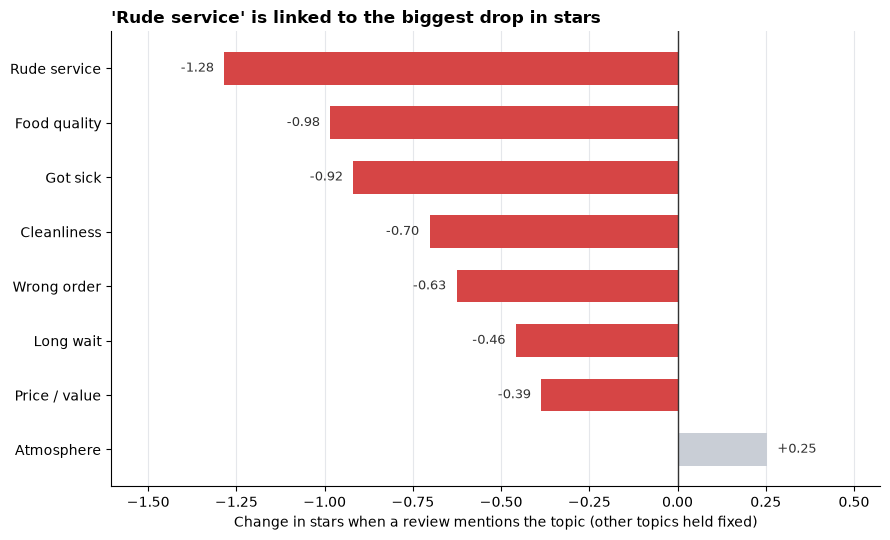

In [18]:
# Chart: stars lost when a review mentions each complaint (others held fixed)
plot_data = star_cost.sort_values("star_gap_others_fixed", ascending=False)   # most costly ends up at the top
colors = ["#D64545" if gap < 0 else "#C9CED6" for gap in plot_data.star_gap_others_fixed]  # red = linked to fewer stars

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_data.index, plot_data.star_gap_others_fixed, color=colors, height=0.6)
ax.axvline(0, color="#333333", linewidth=1)

for y, gap in enumerate(plot_data.star_gap_others_fixed):
    # put the label just past the end of each bar (left side for negative bars, right side for positive)
    ax.text(gap + (-0.03 if gap < 0 else 0.03), y, f"{gap:+.2f}", va="center",
            ha="right" if gap < 0 else "left", fontsize=9, color="#333333")

worst = star_cost.index[0]
ax.set_title(f"'{worst}' is linked to the biggest drop in stars", loc="left", fontweight="bold")
ax.set_xlabel("Change in stars when a review mentions the topic (other topics held fixed)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
lo = plot_data.star_gap_others_fixed.min()
ax.set_xlim(lo * 1.25, max(plot_data.star_gap_others_fixed.max(), 0) + abs(lo) * 0.25)
plt.tight_layout()
plt.show()

### 2. Have complaints changed over the years?

For every year, we work out what share of that year's **negative** reviews mention each topic. Each topic gets its own small chart so the lines don't pile on top of each other. The grey band marks **2020 (COVID)**.

Same rules as the EDA notebook: **2022 is hidden** (the data stops on 19 January 2022), and so are years with too few negative reviews to trust.

Note that each small chart has its **own vertical scale**, so compare the *shape* of the lines (rising, falling, flat), not their heights.

In [19]:
# COMPLAINTS OVER TIME
MIN_YEAR_NEGATIVE = 300     # hide years with fewer negative reviews than this (too little data to trust)

# The year isn't in our reviews table yet, so fetch it from the database and attach it by review_id
years = pd.read_sql_query(text("SELECT review_id, review_year, is_partial_year FROM clean.reviews"), engine)
neg_years = negative_reviews.merge(years, on="review_id", how="left").dropna(subset=["review_year"])
neg_years["review_year"] = neg_years["review_year"].astype(int)

# One row per year: number of negative reviews, whether the year is partial, and the share mentioning each topic.
# The ** unpacks a dictionary into named calculations: {"Long wait": ("Long wait", "mean"), ...}
by_year = neg_years.groupby("review_year").agg(
    negative_reviews=("review_id", "count"),
    partial=("is_partial_year", "max"),
    **{topic: (topic, "mean") for topic in topic_names},
)
trend = by_year[(by_year.negative_reviews >= MIN_YEAR_NEGATIVE) & (by_year.partial == 0)]
first, last = trend.index.min(), trend.index.max()
print(f"Years shown: {first} to {last}\n")

# Change in percentage points (pp) between key years; e.g. 30% -> 34% is +4 pp
change = pd.DataFrame({
    f"{first}": trend.loc[first, topic_names] * 100,
    "2019": trend.loc[2019, topic_names] * 100 if 2019 in trend.index else np.nan,
    "2020": trend.loc[2020, topic_names] * 100 if 2020 in trend.index else np.nan,
    f"{last}": trend.loc[last, topic_names] * 100,
})
change[f"change {first}->{last} (pp)"] = change[f"{last}"] - change[f"{first}"]
change["COVID change 2019->2020 (pp)"] = change["2020"] - change["2019"]
print(change.round(1).sort_values(f"change {first}->{last} (pp)", ascending=False).to_string())

Years shown: 2009 to 2021

               2009  2019  2020  2021  change 2009->2021 (pp)  COVID change 2019->2020 (pp)
Rude service   12.2  22.0  21.3  21.6                     9.4                          -0.7
Long wait      27.6  36.1  32.1  35.4                     7.8                          -4.0
Wrong order     5.5   7.7   8.2   7.8                     2.2                           0.5
Got sick        3.3   3.1   3.0   2.7                    -0.6                          -0.1
Cleanliness     9.0   8.6   7.4   7.9                    -1.0                          -1.2
Food quality   37.8  33.8  32.1  32.5                    -5.2                          -1.6
Price / value  32.2  28.3  26.1  26.5                    -5.7                          -2.2
Atmosphere     16.0   7.6   4.8   5.1                   -11.0                          -2.8


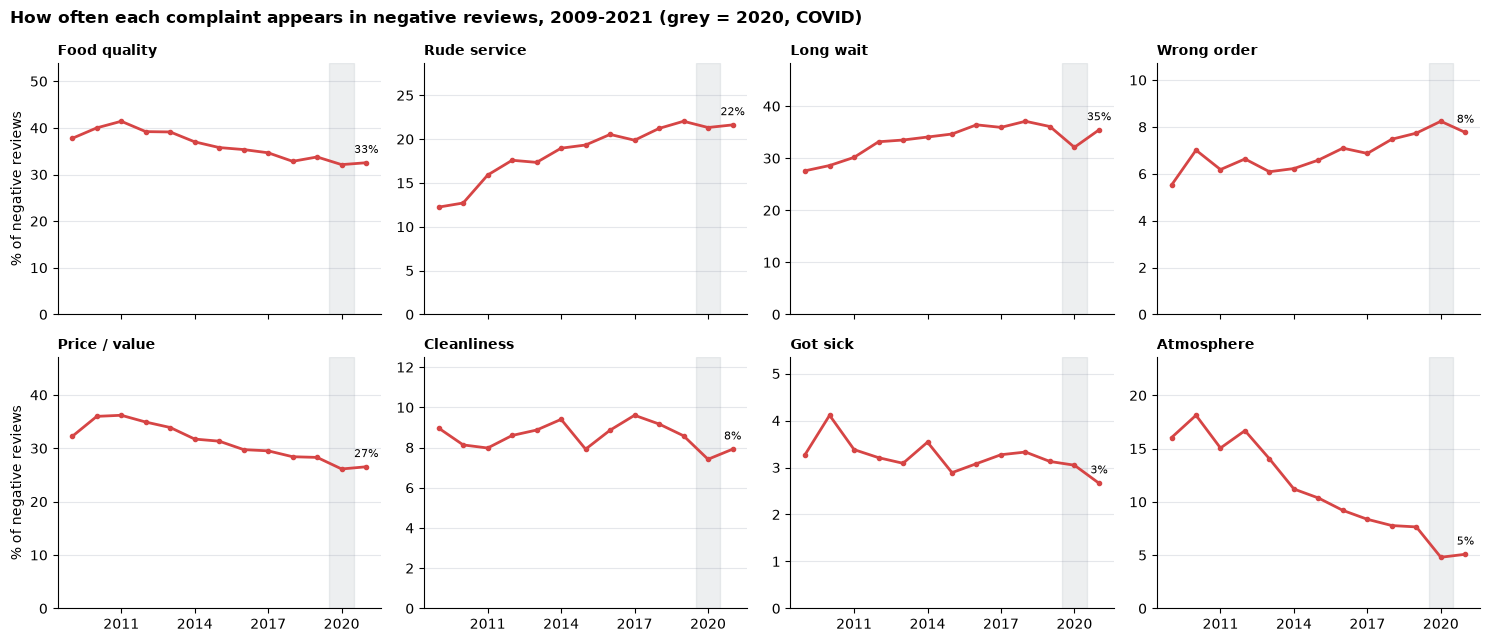

In [20]:
# Chart: one small line chart per topic (called "small multiples")
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)

for ax, topic in zip(axes.flat, topic_names):           # axes.flat walks through the 2x4 grid one panel at a time
    values = trend[topic] * 100
    ax.plot(trend.index, values, color="#D64545", linewidth=2, marker="o", markersize=3)
    ax.axvspan(2019.5, 2020.5, color="#8A94A0", alpha=0.15)        # grey band = 2020 (COVID)
    ax.set_title(topic, loc="left", fontsize=10, fontweight="bold")
    ax.set_ylim(0, values.max() * 1.3)                  # start at 0 so changes aren't exaggerated
    ax.annotate(f"{values.iloc[-1]:.0f}%", (trend.index[-1], values.iloc[-1]),   # label the latest value
                textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))   # whole years only (no "2017.5")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)
    ax.set_axisbelow(True)

for ax in axes[:, 0]:                                  # first column of panels only
    ax.set_ylabel("% of negative reviews")
fig.suptitle(f"How often each complaint appears in negative reviews, {first}-{last} (grey = 2020, COVID)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 3. Do different kinds of restaurants get different complaints?

We attach each negative review to its restaurant's category tags (Pizza, Mexican, Chinese...) and work out how often each complaint appears **within that cuisine**.

The heatmap shows how far each cuisine is from the **average for all restaurants**:
- **Red** means the complaint is **more common** there than usual.
- **Blue** means it is **less common**.
- Each square's number is the actual share of that cuisine's negative reviews.

As in the EDA, generic tags that don't describe the food ("Restaurants", "Nightlife", "Event Planning"...) are left out. So are cuisines with too few negative reviews to trust. A restaurant can have several tags, so one review can count towards several cuisines.

In [21]:
# COMPLAINTS BY CUISINE
from matplotlib.colors import TwoSlopeNorm

MIN_NEGATIVE_PER_CUISINE = 1000    # only cuisines with at least this many negative reviews
TOP_N = 15                         # show the 15 biggest cuisines so the chart stays readable
NOT_CUISINES = ["Restaurants", "Food", "Event Planning & Services", "Arts & Entertainment",
                "Venues & Event Spaces", "Specialty Food", "Caterers", "Beer", "Wine & Spirits",
                "Nightlife", "Bars"] + MIXED_TAGS      # same generic list as the EDA, plus the mixed-business tags

categories = pd.read_sql_query(text("SELECT business_id, category FROM clean.business_categories"), engine)

# One row per (negative review, tag): a review appears once for every tag its restaurant has
neg_cat = negative_reviews[["review_id", "business_id"] + topic_names].merge(categories, on="business_id")

counts = neg_cat.groupby("category").size()
keep = counts[(counts >= MIN_NEGATIVE_PER_CUISINE) & (~counts.index.isin(NOT_CUISINES))]
cuisines = keep.sort_values(ascending=False).head(TOP_N).index

by_cuisine = neg_cat[neg_cat.category.isin(cuisines)].groupby("category")[topic_names].mean()
by_cuisine = by_cuisine.loc[cuisines]                   # keep biggest cuisine at the top
overall = negative_reviews[topic_names].mean()          # the all-restaurant average for each topic
diff_pp = (by_cuisine - overall) * 100                  # pandas lines up the topic columns automatically

print("Share of negative reviews mentioning each topic (%):")
print((by_cuisine * 100).round(1).to_string())

Share of negative reviews mentioning each topic (%):
                        Food quality  Rude service  Long wait  Wrong order  Price / value  Cleanliness  Got sick  Atmosphere
category                                                                                                                    
American (Traditional)          35.7          22.6       40.3          7.5           29.1          9.4       3.0        10.8
American (New)                  35.5          21.8       40.0          7.6           32.8          8.5       3.0        13.2
Breakfast & Brunch              34.9          20.3       39.3          7.5           28.9          9.3       2.6        10.4
Sandwiches                      33.9          19.4       32.3          6.8           27.4          7.8       2.5         6.5
Burgers                         33.4          21.8       40.8          8.0           23.9          9.3       2.7         6.9
Seafood                         38.5          20.9       35.7          6

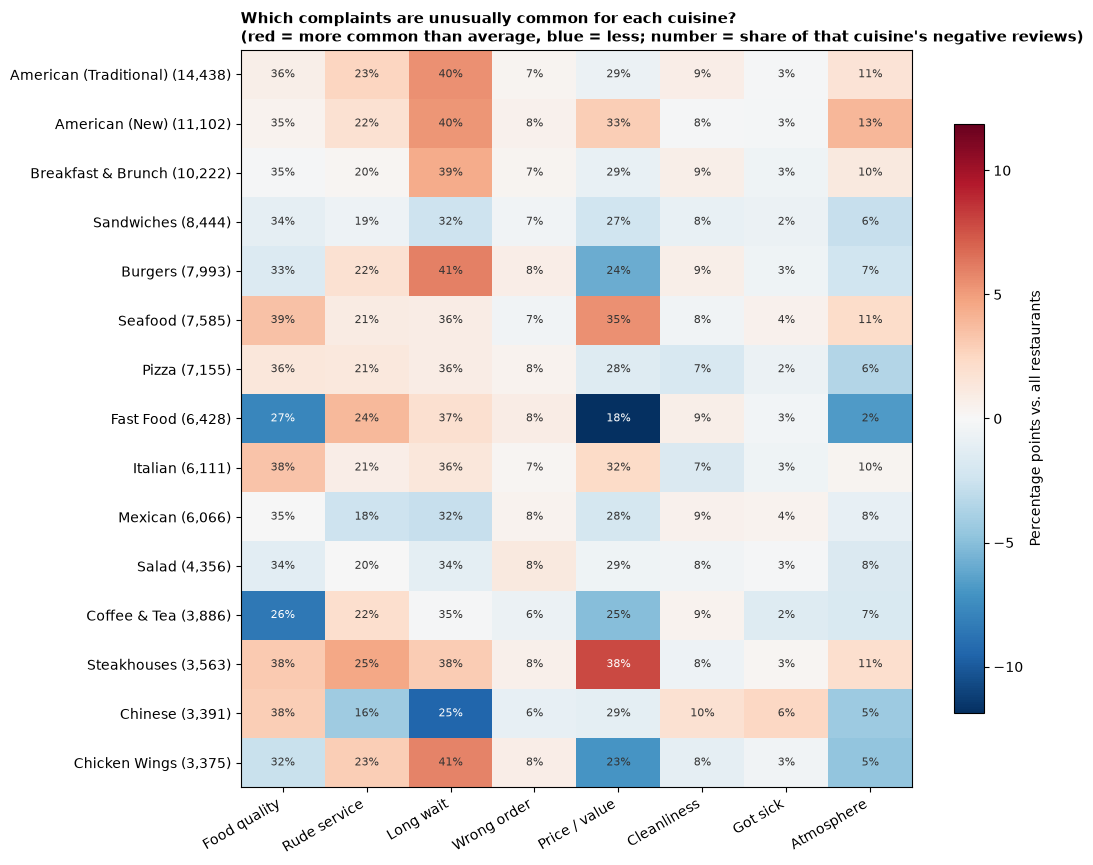

In [22]:
# Chart: heatmap of how each cuisine differs from the average
limit = np.abs(diff_pp.to_numpy()).max()                # make the colour scale symmetric around 0
norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit) # 0 = white (same as average), red above, blue below

fig, ax = plt.subplots(figsize=(11, 0.45 * len(diff_pp) + 2))
img = ax.imshow(diff_pp.to_numpy(), cmap="RdBu_r", norm=norm, aspect="auto")

# Write the actual share inside each square; white text on dark squares so it stays readable
for r in range(diff_pp.shape[0]):
    for c in range(diff_pp.shape[1]):
        dark = abs(diff_pp.iat[r, c]) > limit * 0.6
        ax.text(c, r, f"{by_cuisine.iat[r, c]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if dark else "#333333")

ax.set_xticks(range(len(topic_names)), topic_names, rotation=30, ha="right")
ax.set_yticks(range(len(diff_pp)), [f"{name} ({keep[name]:,})" for name in diff_pp.index])
cbar = fig.colorbar(img, ax=ax, shrink=0.8)
cbar.set_label("Percentage points vs. all restaurants")
ax.set_title("Which complaints are unusually common for each cuisine?\n"
             "(red = more common than average, blue = less; number = share of that cuisine's negative reviews)",
             loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 4. Export summary tables for the dashboard

The dashboard never touches the raw reviews. It reads these small CSV files from `data/summary/`, so every number on it traces back to this notebook.

In [23]:
# EXPORT SUMMARY TABLES
from pathlib import Path

out = Path("../data/summary")              # ".." = one folder up from notebooks/, i.e. the project folder
out.mkdir(parents=True, exist_ok=True)     # create the folder if it doesn't exist yet

topic_summary.round(4).to_csv(out / "topics_overall.csv", index_label="topic")
star_cost.round(4).to_csv(out / "topics_star_cost.csv")
trend.round(4).to_csv(out / "topics_by_year.csv")
by_cuisine.assign(negative_reviews=keep[cuisines]).round(4).to_csv(out / "topics_by_cuisine.csv", index_label="cuisine")

for file in sorted(out.glob("topics_*.csv")):
    print(f"saved {file.name}  ({file.stat().st_size / 1024:.1f} KB)")

saved topics_by_cuisine.csv  (1.2 KB)
saved topics_by_year.csv  (1.0 KB)
saved topics_overall.csv  (0.3 KB)
saved topics_star_cost.csv  (0.5 KB)


### Findings (fill in after running)

Write 1-2 sentences for each, in plain language a restaurant owner would understand:

1. **Most common complaints:**
2. **Most costly complaints (biggest star drop):**
3. **Change over time / COVID:**
4. **Cuisine differences worth noting:**

*Caution: topics come from keyword lists, so they are approximate, and the results show links to low ratings, not causes.*